# 07 · เปรียบเทียบ label จาก AI 3 ตัว กับ Final_Gold_v1

อ่านไฟล์ใน `datasets/workbooks/`:

| ไฟล์ | ใช้ทำอะไร |
|---|---|
| `Gold Set - [Claude] Opus 5.5 Effort-Extra High.xlsx` | label + หลักฐานของ Claude |
| `Gold Set - [Gemini]- 4 Argon Effort-High.xlsx` | label + หลักฐานของ Gemini |
| `Gold Set - [OpenAI] GPT-6.0 Astra Effort-Extra High.xlsx` | label + หลักฐานของ GPT |
| `Final_Gold_v1.xlsx` | label สุดท้าย (ชีต `Final_Gold_150`) |

**อ่านผลอย่างระวัง:** `Final_Gold_v1` ตัดสินจาก label ของ AI ทั้ง 3 ตัวนี้เอง ข้อที่ AI ตอบตรงกันทั้ง 3 ตัวจึง “ถูก” ทุกตัวโดยอัตโนมัติ
ตัวเลขที่บอกความต่างจริงคือผลบน **ข้อที่ AI เห็นไม่ตรงกัน** (กราฟ 4) และนี่ไม่ใช่ gold set จากผู้เชี่ยวชาญที่เป็นคน
หลักฐานของ Gemini ในไฟล์ปัจจุบันถูกแก้ 15 แถวแล้ว (แทนข้อความที่หาไม่เจอในรายงานด้วยข้อความจริง) ผลในกราฟ 7 จึงเป็นของฉบับที่แก้แล้ว

## นิยามศัพท์

**ผู้ติด label (labeler / rater)** — ในชุดนี้คือ AI 3 ตัว: Claude Opus 5.5, Gemini 4 Argon, GPT-6.0 Astra แต่ละตัวให้ label กับ claim ครบทั้ง 150 ข้อ

**Label** — คำตัดสินของ claim หนึ่งข้อ (ตาม `datasets/annotation_guidelines.md`)
- **SUPPORTED** — รายงาน SEC ยืนยันได้ว่า**ทุก**ส่วนสำคัญของ claim เป็นจริง
- **CONTRADICTED** — รายงานแสดงว่า**อย่างน้อยหนึ่ง**ส่วนสำคัญเป็นเท็จ
- **INSUFFICIENT_EVIDENCE** (ในกราฟย่อเป็น INSUFFICIENT) — รายงานไม่ยืนยันและไม่หักล้างส่วนสำคัญบางส่วน

**หมวด claim**
- **Numerical (ตัวเลข)** — ตรวจได้จากตัวเลขในงบโดยตรง เช่น รายได้โตเกิน 10%, operating margin เกิน 20%
- **Interpretive (ตีความ)** — อ้างสาเหตุหรือปัจจัยขับเคลื่อน ซึ่งต้องดูคำอธิบายใน MD&A เช่น “กำไรเพิ่มเพราะทำงานมีประสิทธิภาพขึ้น”
- **Ambiguous (กำกวม)** — หลักฐานชี้ได้หลายทาง หรือข้อสรุปขึ้นกับการตีความ เช่น “ผลประกอบการแข็งแกร่งโดยไม่ได้รับผลกระทบจาก…”

**รูปแบบความเห็นของ AI 3 ตัวต่อ claim หนึ่งข้อ**

| คำในตาราง | คำในกราฟ | นิยาม |
|---|---|---|
| **ตรงกันทั้ง 3 ตัว** | All 3 agree | ทั้ง 3 ตัวให้ label เดียวกัน (unanimous) |
| **2 ต่อ 1** | 2 vs 1 | 2 ตัวให้ label เดียวกัน อีก 1 ตัวต่างออกไป (เสียงข้างมาก 2 ใน 3) |
| **ต่างกันทั้ง 3 ตัว** | All 3 differ | ทั้ง 3 ตัวให้ label คนละแบบ ไม่มีเสียงข้างมาก |
| **เห็นต่าง** | Disputed | ไม่ได้ตรงกันทั้ง 3 ตัว = “2 ต่อ 1” + “ต่างกันทั้ง 3 ตัว” ข้อเหล่านี้คือข้อที่ต้องส่งผู้ตัดสิน (adjudication) |

เปอร์เซ็นต์ในตารางคิดจากจำนวน claim ในแถวนั้น เช่น ตรงกัน 116 จาก 150 = 77.3%

**Final_Gold_v1** — label สุดท้ายในชีต `Final_Gold_150` ที่ตัดสินจาก label ของ AI ทั้ง 3 ตัว ใช้เป็นคำตอบอ้างอิงใน notebook นี้

**ตัวชี้วัด**
- **Agreement / Accuracy (% ตรงกับ Final_Gold_v1)** — สัดส่วน claim ที่โมเดลให้ label เหมือน Final_Gold_v1
- **Macro-F1** — คำนวณ F1 แยกทีละ label แล้วเฉลี่ยแบบให้น้ำหนักเท่ากัน ไม่เอนเข้าหา label ที่มีจำนวนเยอะ
- **Cohen's κ** — ความเห็นตรงกันของผู้ติด label **2 คน** หลังหักส่วนที่ตรงกันโดยบังเอิญ (1 = ตรงกันสมบูรณ์, 0 = เท่ากับสุ่ม)
- **Fleiss' κ / Krippendorff's α** — ความเห็นตรงกันของผู้ติด label **ทั้งกลุ่ม** หลังหักส่วนที่ตรงกันโดยบังเอิญ (รายละเอียดในหัวข้อ 2)
- **95% CI (bootstrap)** — ช่วงความเชื่อมั่น 95% ได้จากการสุ่ม claim ซ้ำ 2,000 รอบ ช่วงยิ่งกว้างแปลว่าค่ายิ่งไม่แน่นอน
- **Confusion matrix** — ตารางนับว่า claim ที่ label สุดท้ายเป็น X ถูกโมเดลตอบเป็นอะไรบ้าง เส้นทแยงคือข้อที่ตอบตรง

**คุณภาพหลักฐาน (หัวข้อ 7)**
- **Verbatim (ตรงคำต่อคำ)** — ข้อความที่คัดลอกมามีอยู่ในรายงาน SEC จริง (ต่างแค่ช่องว่าง/เครื่องหมายได้)
- **Reformatted, numbers match (ตัวเลขตรง แต่เรียบเรียงใหม่)** — เช่น พิมพ์แถวตารางใหม่ ถ้อยคำไม่ตรง แต่ตัวเลขทุกตัวพบในรายงาน
- **Not found (หาไม่เจอ)** — ทั้งถ้อยคำและตัวเลขไม่พบในรายงาน อาจแต่งขึ้นหรือคัดลอกผิดฉบับ

In [1]:
import os, sys, re, collections
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
for p in (ROOT, os.path.join(ROOT, "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(ROOT)
import warnings; warnings.filterwarnings("ignore", module="openpyxl")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from openpyxl import load_workbook
%matplotlib inline

import annotation_workbook as aw
from engine.corpus import document_text
from engine.datasets import cohen_kappa, load_split
from engine.metrics import classification_metrics
from engine.schema import LABELS

WB = "datasets/workbooks"
MODEL_FILES = {
    "Claude Opus 5.5": f"{WB}/Gold Set - [Claude] Opus 5.5 Effort-Extra High.xlsx",
    "Gemini 4 Argon": f"{WB}/Gold Set - [Gemini]- 4 Argon Effort-High.xlsx",
    "GPT-6.0 Astra": f"{WB}/Gold Set - [OpenAI] GPT-6.0 Astra Effort-Extra High.xlsx",
}
FINAL_FILE = f"{WB}/Final_Gold_v1.xlsx"
MODELS = list(MODEL_FILES)

# Reference palette: categorical slots 1-3 (validated all-pairs), neutral ink for the final label,
# one-hue blue ramp for magnitude, reserved status colors for verified / partly / not found.
COLOR = {"Claude Opus 5.5": "#2a78d6", "Gemini 4 Argon": "#eb6834", "GPT-6.0 Astra": "#1baf7a", "Final_Gold_v1": "#52514e"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#104281"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "critical": "#d03b3b"}
SHORT = {"SUPPORTED": "SUPPORTED", "CONTRADICTED": "CONTRADICTED", "INSUFFICIENT_EVIDENCE": "INSUFFICIENT"}

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 11,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110,
})
FIG_DIR = "results/figures"; os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/07_{name}.png", bbox_inches="tight", dpi=150)
print("research root:", ROOT)

research root: /Users/somchx/.local/share/kilo/worktree-pool/invesment-23ce5a1cc8f6/resolute-muskmelon/research


## โหลดข้อมูล
label ของ AI อ่านจากไฟล์ของแต่ละโมเดลโดยตรง ส่วน label สุดท้ายอ่านจากชีต `Final_Gold_150`

In [2]:
def read_model(path):
    wb = load_workbook(path, read_only=True)
    rows = list(wb["Claims"].iter_rows(values_only=True)); col = {h: i for i, h in enumerate(rows[0])}
    labels = {r[0]: r[col[aw.H_LABEL]] for r in rows[1:] if r[0]}
    evidence = [r[:8] for r in wb["Evidence"].iter_rows(min_row=2, values_only=True) if r[0]]
    return labels, evidence

labels, evidence = {}, {}
for m, f in MODEL_FILES.items():
    labels[m], evidence[m] = read_model(f)

final = pd.read_excel(FINAL_FILE, sheet_name="Final_Gold_150").set_index("Claim ID")["Final Gold Label [EDIT]"]
claims = {c.claim_id: c for c in load_split("gold")}
df = pd.DataFrame({
    "company": {k: c.company for k, c in claims.items()},
    "category": {k: c.claim_category for k, c in claims.items()},
    **{m: labels[m] for m in MODELS},
    "Final_Gold_v1": final,
}).loc[sorted(claims)]
n_labels = df[MODELS].nunique(axis=1)
df["vote"] = n_labels.map({1: "All 3 agree", 2: "2 vs 1", 3: "All 3 differ"})
df["disputed"] = n_labels > 1

missing = df[MODELS + ["Final_Gold_v1"]].isna().sum()
print("claims:", len(df), "| missing labels:", dict(missing[missing > 0]) or "none")
cmp = pd.read_excel(FINAL_FILE, sheet_name="Compare_150").set_index("Claim ID")
stale = {m: int((cmp[c].reindex(df.index) != df[m]).sum()) for m, c in
         zip(MODELS, ["Claude Label", "Gemini Label", "GPT-6 Astra Label"])}
print("labels in Compare_150 that differ from the current model files:", stale)
df.head()

claims: 150 | missing labels: none
labels in Compare_150 that differ from the current model files: {'Claude Opus 5.5': 0, 'Gemini 4 Argon': 0, 'GPT-6.0 Astra': 0}


,company,category,Claude Opus 5.5,Gemini 4 Argon,GPT-6.0 Astra,Final_Gold_v1,vote,disputed
GOLD-AAPL-01,AAPL,numerical,SUPPORTED,SUPPORTED,SUPPORTED,SUPPORTED,All 3 agree,False
GOLD-AAPL-02,AAPL,numerical,SUPPORTED,SUPPORTED,SUPPORTED,SUPPORTED,All 3 agree,False
GOLD-AAPL-03,AAPL,numerical,SUPPORTED,SUPPORTED,SUPPORTED,SUPPORTED,All 3 agree,False
GOLD-AAPL-04,AAPL,numerical,INSUFFICIENT_EVIDENCE,INSUFFICIENT_EVIDENCE,INSUFFICIENT_EVIDENCE,INSUFFICIENT_EVIDENCE,All 3 agree,False
GOLD-AAPL-05,AAPL,numerical,CONTRADICTED,CONTRADICTED,CONTRADICTED,CONTRADICTED,All 3 agree,False


## 1 · Final_Gold_v1 มาจากการโหวตแบบไหน
ยิ่งแท่ง “All 3 agree” ยาว label สุดท้ายยิ่งเป็นแค่การยืนยันสิ่งที่ AI ตอบเหมือนกันอยู่แล้ว

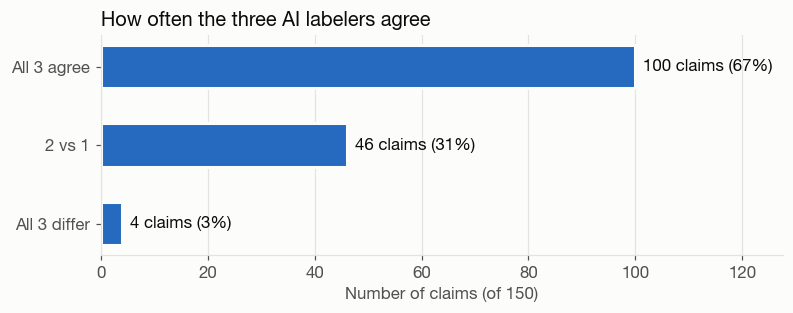

In [3]:
order = ["All 3 agree", "2 vs 1", "All 3 differ"]
counts = df["vote"].value_counts().reindex(order, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(order[::-1], counts[order[::-1]], color=BLUES[4], height=0.55, edgecolor=SURFACE, linewidth=2)
for b, v in zip(bars, counts[order[::-1]]):
    ax.text(b.get_width() + 1.5, b.get_y() + b.get_height() / 2, f"{v} claims ({v / len(df):.0%})", va="center", color=INK)
ax.set_xlim(0, len(df) * 0.85); ax.grid(axis="y", visible=False); ax.set_xlabel("Number of claims (of 150)")
ax.set_title("How often the three AI labelers agree")
save(fig, "vote_pattern"); plt.show()

ตารางสรุปแยกตามหมวด claim (คำนิยามอยู่ในหัวข้อ “นิยามศัพท์” ด้านบน)

**หมายเหตุเรื่องตัวเลข:** ตารางนี้คำนวณจากไฟล์ AI ชุดปัจจุบันในโฟลเดอร์ `datasets/workbooks/` ส่วนตัวเลข 116 / 34 / 0 ที่เคยรายงานไว้ (Numerical 50/0, Interpretive 32/18, Ambiguous 34/16) มาจากไฟล์ Review A/B/C ชุดก่อน (`datasets/llm_annotations/`) ซึ่ง Gemini เป็นคนละรอบกับไฟล์ปัจจุบัน cell ถัดไปคำนวณชุดนั้นให้เทียบด้วย

In [4]:
def agreement_table(frame, cols):
    n = frame[cols].nunique(axis=1)
    rows = []
    for name, sub in [*[(c.capitalize(), frame[frame.category == c]) for c in ["numerical", "interpretive", "ambiguous"]], ("รวม", frame)]:
        k = n.loc[sub.index]
        rows.append({"ประเภท Claim": name, "ทั้งหมด": len(sub), "ตรงกันทั้ง 3 ตัว": int((k == 1).sum()),
                     "เห็นต่าง": int((k > 1).sum()), "  ↳ 2 ต่อ 1": int((k == 2).sum()), "  ↳ ต่างกันทั้ง 3 ตัว": int((k == 3).sum()),
                     "% ตรงกัน": f"{(k == 1).mean():.1%}", "% เห็นต่าง": f"{(k > 1).mean():.1%}"})
    return pd.DataFrame(rows).set_index("ประเภท Claim")

print("ไฟล์ AI ชุดปัจจุบัน (datasets/workbooks/)")
agreement_table(df, MODELS)

ไฟล์ AI ชุดปัจจุบัน (datasets/workbooks/)


,ทั้งหมด,ตรงกันทั้ง 3 ตัว,เห็นต่าง,↳ 2 ต่อ 1,↳ ต่างกันทั้ง 3 ตัว,% ตรงกัน,% เห็นต่าง
ประเภท Claim,,,,,,,
Numerical,50,46,4,4,0,92.0%,8.0%
Interpretive,50,28,22,18,4,56.0%,44.0%
Ambiguous,50,26,24,24,0,52.0%,48.0%
รวม,150,100,50,46,4,66.7%,33.3%


In [5]:
from engine.datasets import load_annotations
old = collections.defaultdict(dict)
for a in load_annotations("datasets/llm_annotations"):
    old[a.claim_id][a.reviewer_id] = a.gold_label
old_df = pd.DataFrame(old).T.loc[df.index].join(df[["category"]])
print("ไฟล์ Review A/B/C ชุดก่อน (datasets/llm_annotations/):", ", ".join(c for c in old_df.columns if c != "category"))
agreement_table(old_df, [c for c in old_df.columns if c != "category"])

ไฟล์ Review A/B/C ชุดก่อน (datasets/llm_annotations/): rev_cedric, rev_gastra, rev_gemna


,ทั้งหมด,ตรงกันทั้ง 3 ตัว,เห็นต่าง,↳ 2 ต่อ 1,↳ ต่างกันทั้ง 3 ตัว,% ตรงกัน,% เห็นต่าง
ประเภท Claim,,,,,,,
Numerical,50,50,0,0,0,100.0%,0.0%
Interpretive,50,32,18,18,0,64.0%,36.0%
Ambiguous,50,34,16,16,0,68.0%,32.0%
รวม,150,116,34,34,0,77.3%,22.7%


## 2 · ความน่าเชื่อถือของการติด label: Fleiss' κ และ Krippendorff's α

กราฟ 1 นับว่าตอบตรงกันกี่ข้อ แต่การนับแบบนั้นไม่ได้หักส่วนที่ **ตรงกันโดยบังเอิญ** ออก ถ้าผู้ติด label ทุกคนชอบตอบ SUPPORTED อยู่แล้ว ก็จะตรงกันบ่อยแม้ไม่ได้อ่านหลักฐานเลย ค่าสองตัวนี้แก้ปัญหานั้น

| ค่า | ใช้เมื่อ | จุดเด่น |
|---|---|---|
| **Cohen's κ** | ผู้ติด label **2 คน** | ใช้ใน notebook 02 และกราฟ 4 (เทียบทีละคู่) |
| **Fleiss' κ** | ผู้ติด label **ตั้งแต่ 2 คนขึ้นไป** และทุกข้อมีจำนวนผู้ติด label เท่ากัน | สรุปความเห็นตรงกันของทั้งกลุ่มเป็นตัวเลขเดียว |
| **Krippendorff's α** | ผู้ติด label กี่คนก็ได้ **ยอมให้บางข้อขาด label** และเลือกระดับข้อมูลได้ (nominal, ordinal, interval) | ยืดหยุ่นที่สุด ใช้กันมากในงาน annotation |

label ทั้ง 3 แบบไม่มีลำดับ จึงใช้ระดับ **nominal** และในชุดนี้ทุกข้อมีครบ 3 label ค่าทั้งสองจึงใกล้กันมาก

**Fleiss' κ** — ให้ $N$ = จำนวน claim, $n$ = จำนวนผู้ติด label ต่อข้อ, $n_{ij}$ = จำนวนผู้ที่ให้ label $j$ กับ claim $i$

$$\bar P = \frac{1}{N}\sum_i \frac{\sum_j n_{ij}^2 - n}{n(n-1)}, \qquad \bar P_e = \sum_j p_j^2,\; p_j = \frac{1}{Nn}\sum_i n_{ij}, \qquad \kappa = \frac{\bar P - \bar P_e}{1 - \bar P_e}$$

**Krippendorff's α** — $D_o$ = ความไม่ตรงกันที่เกิดขึ้นจริง, $D_e$ = ความไม่ตรงกันที่คาดว่าจะเกิดโดยบังเอิญ (คำนวณจาก coincidence matrix ของคู่ label ภายในแต่ละ claim)

$$\alpha = 1 - \frac{D_o}{D_e}$$

ค่า 1 = ตรงกันสมบูรณ์, 0 = ตรงกันเท่ากับการสุ่ม, ติดลบ = ตรงกันน้อยกว่าการสุ่ม

**เกณฑ์การอ่านค่า**
- Fleiss' κ (Landis & Koch, 1977): < 0 แย่, 0.00–0.20 เล็กน้อย, 0.21–0.40 พอใช้, 0.41–0.60 ปานกลาง, 0.61–0.80 ค่อนข้างมาก, 0.81–1.00 เกือบสมบูรณ์
- Krippendorff's α (Krippendorff, 2004): ≥ 0.800 เชื่อถือได้, 0.667–0.800 ใช้สรุปได้อย่างระมัดระวัง, < 0.667 ไม่ควรใช้

ช่วงความเชื่อมั่น 95% คำนวณด้วย bootstrap สุ่ม claim ซ้ำ 2,000 รอบ (seed คงที่ ผลซ้ำได้)

**ข้อควรระวัง:** ผู้ติด label ทั้ง 3 เป็น AI ค่าเหล่านี้จึงวัดว่า **AI ตอบเหมือนกันแค่ไหน** ไม่ใช่ความน่าเชื่อถือของผู้เชี่ยวชาญที่เป็นคน และความเห็นตรงกันไม่ได้แปลว่าตอบถูก ถ้าทุกตัวพลาดแบบเดียวกัน ค่าก็ยังสูงได้ ในหมวดที่ label เกือบทั้งหมดเป็นค่าเดียว κ อาจต่ำผิดคาดแม้ตอบตรงกันเกือบทุกข้อ (kappa paradox) ต้องดูคู่กับ % ที่ตรงกันเสมอ

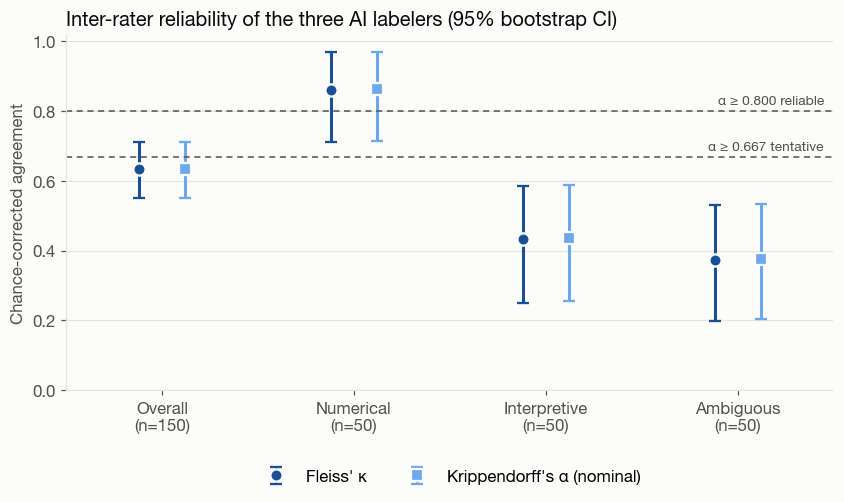

,group,n,pct_all_agree,fleiss_kappa,fleiss_ci95,fleiss_reading,kripp_alpha,kripp_ci95,kripp_reading
0,Overall,150,0.667,0.634,"[0.55, 0.71]",Substantial,0.634,"[0.55, 0.71]",Below 0.667
1,Numerical,50,0.920,0.861,"[0.71, 0.97]",Almost perfect,0.862,"[0.71, 0.97]",Reliable (≥ 0.800)
2,Interpretive,50,0.560,0.432,"[0.25, 0.59]",Moderate,0.436,"[0.26, 0.59]",Below 0.667
3,Ambiguous,50,0.520,0.373,"[0.20, 0.53]",Fair,0.377,"[0.20, 0.53]",Below 0.667


In [6]:
from engine.datasets import fleiss_kappa, krippendorff_alpha_nominal, bootstrap_agreement

def landis_koch(k):
    if k is None or np.isnan(k): return "—"
    for cut, name in ((0, "Poor"), (0.20, "Slight"), (0.40, "Fair"), (0.60, "Moderate"), (0.80, "Substantial")):
        if k <= cut: return name
    return "Almost perfect"
def kripp_band(a):
    if a is None or np.isnan(a): return "—"
    return "Reliable (≥ 0.800)" if a >= 0.8 else "Tentative (0.667–0.800)" if a >= 0.667 else "Below 0.667"

groups = {"Overall": df, **{c.capitalize(): df[df.category == c] for c in ["numerical", "interpretive", "ambiguous"]}}
irr_rows = []
for g, sub in groups.items():
    units = sub[MODELS].values.tolist()
    fk, ka = fleiss_kappa(units), krippendorff_alpha_nominal(units)
    (fk_lo, fk_hi), (ka_lo, ka_hi) = bootstrap_agreement(units, fleiss_kappa), bootstrap_agreement(units, krippendorff_alpha_nominal)
    irr_rows.append({"group": g, "n": len(units), "pct_all_agree": (sub[MODELS].nunique(axis=1) == 1).mean(),
                     "fleiss_kappa": fk, "fleiss_ci95": f"[{fk_lo:.2f}, {fk_hi:.2f}]", "fleiss_reading": landis_koch(fk),
                     "kripp_alpha": ka, "kripp_ci95": f"[{ka_lo:.2f}, {ka_hi:.2f}]", "kripp_reading": kripp_band(ka),
                     "_fk": (fk_lo, fk_hi), "_ka": (ka_lo, ka_hi)})
irr = pd.DataFrame(irr_rows)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(irr)); off = 0.12
for i, (col, ci, name, color, marker) in enumerate([("fleiss_kappa", "_fk", "Fleiss' κ", BLUES[5], "o"),
                                                     ("kripp_alpha", "_ka", "Krippendorff's α (nominal)", BLUES[2], "s")]):
    xs = x + (i - 0.5) * 2 * off
    lo = irr[col] - irr[ci].map(lambda t: t[0]); hi = irr[ci].map(lambda t: t[1]) - irr[col]
    ax.errorbar(xs, irr[col], yerr=[lo, hi], fmt=marker, color=color, ecolor=color, elinewidth=2, capsize=4,
                markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5, label=name)
for yv, txt in ((0.8, "α ≥ 0.800 reliable"), (0.667, "α ≥ 0.667 tentative")):
    ax.axhline(yv, color=INK2, linewidth=1, linestyle=(0, (4, 3)))
    ax.text(len(irr) - 0.55, yv + 0.012, txt, color=INK2, fontsize=9, ha="right", va="bottom")
ax.set_xticks(x, [f"{g}\n(n={n})" for g, n in zip(irr.group, irr.n)]); ax.set_xlim(-0.5, len(irr) - 0.5)
ax.set_ylim(min(0, (irr.fleiss_kappa.min() - 0.15)), 1.02); ax.grid(axis="x", visible=False)
ax.set_ylabel("Chance-corrected agreement"); ax.set_title("Inter-rater reliability of the three AI labelers (95% bootstrap CI)")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
save(fig, "inter_rater_reliability"); plt.show()

irr.drop(columns=["_fk", "_ka"]).round({"pct_all_agree": 3, "fleiss_kappa": 3, "kripp_alpha": 3})

### 2.1 · % ตรงกัน เทียบกับค่าที่หักความบังเอิญแล้ว แยกตามหมวด

กราฟซ้ายแสดงรูปแบบการโหวตของแต่ละหมวด กราฟขวาเทียบ “% ตรงกันทั้ง 3 ตัว” กับ Fleiss' κ และ Krippendorff's α ของหมวดเดียวกัน เส้นประคือเกณฑ์ของ Krippendorff

ระยะห่างระหว่างจุดสีเทากับจุดสีน้ำเงินมาจาก 2 ส่วน
1. **ความบังเอิญ** — คอลัมน์ `ตรงกันโดยบังเอิญ (P̄e)` ในตาราง คือโอกาสที่สองตัวตอบตรงกันถ้าสุ่มตามสัดส่วน label ของหมวดนั้น κ หักส่วนนี้ออก
2. **วิธีนับ** — % ตรงกันทั้ง 3 ตัวนับแบบเข้ม ข้อ 2 ต่อ 1 ได้ 0 ส่วน κ นับทีละคู่ ข้อ 2 ต่อ 1 ได้ 1 คู่ที่ตรงจาก 3 คู่ (คอลัมน์ `ตรงกันรายคู่ (P̄)`)

หมวด Numerical ตรงกันเกือบทุกข้อจึงผ่านเกณฑ์ ส่วน Interpretive และ Ambiguous แม้ตรงกันเกินครึ่ง แต่หลังหักความบังเอิญแล้วต่ำกว่า 0.667 ชัดเจน

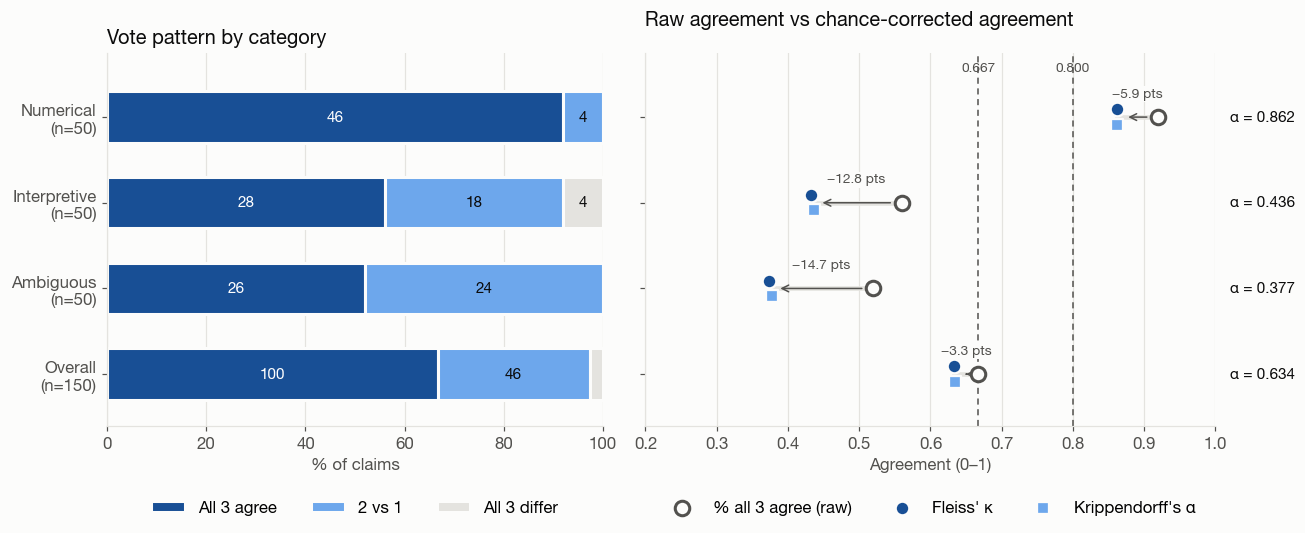

,ตรงกันทั้ง 3 ตัว,2 ต่อ 1,ต่างกันทั้ง 3,ตรงกันรายคู่ (P̄),ตรงกันโดยบังเอิญ (P̄e),Fleiss' κ [95% CI],Krippendorff's α,การแปลผล
หมวด,,,,,,,,
Numerical,46/50 (92.0%),4,0,0.947,0.616,"0.861 [0.71, 0.97]",0.862,เชื่อถือได้ (≥ 0.80)
Interpretive,28/50 (56.0%),18,4,0.680,0.437,"0.432 [0.25, 0.59]",0.436,ต่ำกว่า 0.667
Ambiguous,26/50 (52.0%),24,0,0.680,0.490,"0.373 [0.20, 0.53]",0.377,ต่ำกว่า 0.667
รวม,100/150 (66.7%),46,4,0.769,0.369,"0.634 [0.55, 0.71]",0.634,ต่ำกว่า 0.667


In [7]:
def pairwise_agreement(units):
    """Fleiss' P̄ (observed pairwise agreement) and P̄e (chance agreement)."""
    m, n = len(units[0]), len(units)
    p_bar = np.mean([(sum(v * v for v in collections.Counter(u).values()) - m) / (m * (m - 1)) for u in units])
    tot = collections.Counter(l for u in units for l in u)
    return p_bar, sum((t / (n * m)) ** 2 for t in tot.values())

cat_order = ["Numerical", "Interpretive", "Ambiguous", "Overall"]
nuniq = df[MODELS].nunique(axis=1)
rows = []
for g in cat_order:
    sub = groups[g]; k = nuniq.loc[sub.index]; r = irr.set_index("group").loc[g]
    p_bar, p_e = pairwise_agreement(sub[MODELS].values.tolist())
    rows.append({"group": g, "n": len(sub), "all3": int((k == 1).sum()), "two1": int((k == 2).sum()), "differ": int((k == 3).sum()),
                 "pct": (k == 1).mean(), "p_bar": p_bar, "p_e": p_e, "fk": r.fleiss_kappa, "fk_ci": r.fleiss_ci95,
                 "ka": r.kripp_alpha, "reading": r.kripp_reading})
bycat = pd.DataFrame(rows)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.15], "wspace": 0.08}, sharey=True)
y = np.arange(len(bycat))[::-1]
VOTE_COLOR = {"all3": BLUES[5], "two1": BLUES[2], "differ": "#e4e3df"}
VOTE_NAME = {"all3": "All 3 agree", "two1": "2 vs 1", "differ": "All 3 differ"}
left = np.zeros(len(bycat))
for key in ("all3", "two1", "differ"):
    share = bycat[key] / bycat.n * 100
    axl.barh(y, share, left=left, height=0.6, color=VOTE_COLOR[key], edgecolor=SURFACE, linewidth=2, label=VOTE_NAME[key])
    for yi, l, s, c in zip(y, left, share, bycat[key]):
        if s >= 6:
            axl.text(l + s / 2, yi, str(c), ha="center", va="center", fontsize=10,
                     color="white" if key == "all3" else INK, fontweight="bold" if key == "all3" else "normal")
    left += share
axl.set_xlim(0, 100); axl.set_xlabel("% of claims"); axl.grid(axis="y", visible=False)
axl.set_yticks(y, [f"{g}\n(n={n})" for g, n in zip(bycat.group, bycat.n)])
axl.set_title("Vote pattern by category")
axl.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))

for yi, p, fk, ka in zip(y, bycat.pct, bycat.fk, bycat.ka):
    axr.plot([fk, p], [yi, yi], color=GRID, linewidth=3, solid_capstyle="round", zorder=1)
    axr.annotate("", xy=(fk + 0.012, yi), xytext=(p - 0.012, yi),
                 arrowprops=dict(arrowstyle="->", color=INK2, lw=1), zorder=2)
    axr.text((p + fk) / 2, yi + 0.2, f"−{(p - fk) * 100:.1f} pts", ha="center", va="bottom", fontsize=9, color=INK2, zorder=5,
             bbox=dict(boxstyle="square,pad=0.15", facecolor=SURFACE, edgecolor="none"))
axr.scatter(bycat.pct, y, s=90, facecolor=SURFACE, edgecolor=INK2, linewidth=2, zorder=3, label="% all 3 agree (raw)")
axr.scatter(bycat.fk, y + 0.09, s=80, marker="o", color=BLUES[5], edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Fleiss' κ")
axr.scatter(bycat.ka, y - 0.09, s=70, marker="s", color=BLUES[2], edgecolor=SURFACE, linewidth=1.5, zorder=4, label="Krippendorff's α")
for yi, ka, rd in zip(y, bycat.ka, bycat.reading):
    axr.text(1.02, yi, f"α = {ka:.3f}", va="center", fontsize=10, color=INK, fontweight="bold")
for xv, txt in ((0.667, "0.667"), (0.8, "0.800")):
    axr.axvline(xv, color=INK2, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
    axr.text(xv, y.max() + 0.5, txt, ha="center", va="bottom", fontsize=9, color=INK2)
axr.set_xlim(0.2, 1.0); axr.set_ylim(-0.6, y.max() + 0.75); axr.grid(axis="y", visible=False)
axr.set_xlabel("Agreement (0–1)")
axr.set_title("Raw agreement vs chance-corrected agreement", pad=18)
axr.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
save(fig, "agreement_by_category"); plt.show()

table = pd.DataFrame({
    "หมวด": bycat.group.replace({"Overall": "รวม"}),
    "ตรงกันทั้ง 3 ตัว": [f"{a}/{n} ({p:.1%})" for a, n, p in zip(bycat.all3, bycat.n, bycat.pct)],
    "2 ต่อ 1": bycat.two1, "ต่างกันทั้ง 3": bycat.differ,
    "ตรงกันรายคู่ (P̄)": bycat.p_bar.map("{:.3f}".format), "ตรงกันโดยบังเอิญ (P̄e)": bycat.p_e.map("{:.3f}".format),
    "Fleiss' κ [95% CI]": [f"{k:.3f} {ci}" for k, ci in zip(bycat.fk, bycat.fk_ci)],
    "Krippendorff's α": bycat.ka.map("{:.3f}".format),
    "การแปลผล": bycat.reading.replace({"Reliable (≥ 0.800)": "เชื่อถือได้ (≥ 0.80)", "Below 0.667": "ต่ำกว่า 0.667",
                                        "Tentative (0.667–0.800)": "ใช้ได้อย่างระมัดระวัง"}),
}).set_index("หมวด")
table

Cohen's κ ทีละคู่ ใช้ดูว่าคู่ไหนเห็นตรงกันมาก หรือน้อยเป็นพิเศษ ซึ่ง Fleiss' κ ที่เป็นค่ารวมบอกไม่ได้

- **ช่องในกราฟ** = Cohen's κ ของคู่นั้น (สีเข้ม = ตรงกันมาก) และคำอ่านผลตามเกณฑ์ Landis & Koch ช่องทแยงเป็นการเทียบกับตัวเองจึงเว้นว่าง
- **ตาราง** = % ที่ตอบตรงกันแบบนับตรง ๆ คู่กับ κ ที่หักส่วนที่ตรงกันโดยบังเอิญแล้ว κ จึงต่ำกว่า % เสมอ

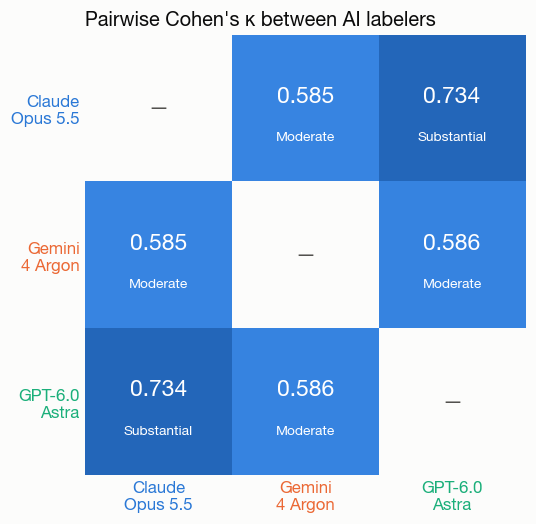

,% ตอบตรงกัน,Cohen's κ,การแปลผล (Landis & Koch)
คู่,,,
Claude Opus 5.5 – Gemini 4 Argon,74.0%,0.585,Moderate
Claude Opus 5.5 – GPT-6.0 Astra,82.7%,0.734,Substantial
Gemini 4 Argon – GPT-6.0 Astra,74.0%,0.586,Moderate


In [8]:
import itertools
pair = pd.DataFrame(np.nan, index=MODELS, columns=MODELS)
pair_rows = []
for a, b in itertools.combinations(MODELS, 2):
    k = cohen_kappa(list(zip(df[a], df[b])))
    pair.loc[a, b] = pair.loc[b, a] = k
    pair_rows.append({"คู่": f"{a} – {b}", "% ตอบตรงกัน": f"{(df[a] == df[b]).mean():.1%}",
                      "Cohen's κ": round(k, 3), "การแปลผล (Landis & Koch)": landis_koch(k)})

fig, ax = plt.subplots(figsize=(6.6, 5.2))
cmap_k = LinearSegmentedColormap.from_list("blue", ["#f3f7fd"] + BLUES)
ax.imshow(pair.values, cmap=cmap_k, vmin=0, vmax=1)
for i in range(len(MODELS)):
    for j in range(len(MODELS)):
        if i == j:
            ax.text(j, i, "—", ha="center", va="center", color=INK2, fontsize=13)
            continue
        v = pair.values[i, j]
        c = "white" if v > 0.55 else INK
        ax.text(j, i - 0.08, f"{v:.3f}", ha="center", va="center", color=c, fontsize=15, fontweight="bold")
        ax.text(j, i + 0.2, landis_koch(v), ha="center", va="center", color=c, fontsize=9)
short = [m.replace(" ", "\n", 1) for m in MODELS]
ax.set_xticks(range(len(MODELS)), short); ax.set_yticks(range(len(MODELS)), short)
for t, m in zip(ax.get_xticklabels(), MODELS): t.set_color(COLOR[m])
for t, m in zip(ax.get_yticklabels(), MODELS): t.set_color(COLOR[m])
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Pairwise Cohen's κ between AI labelers")
save(fig, "pairwise_cohen_kappa"); plt.show()
pd.DataFrame(pair_rows).set_index("คู่")

## 3 · แต่ละโมเดลชอบตอบ label ไหน
เทียบจำนวน label ของ AI แต่ละตัวกับ label สุดท้าย (แท่งสีเทา)

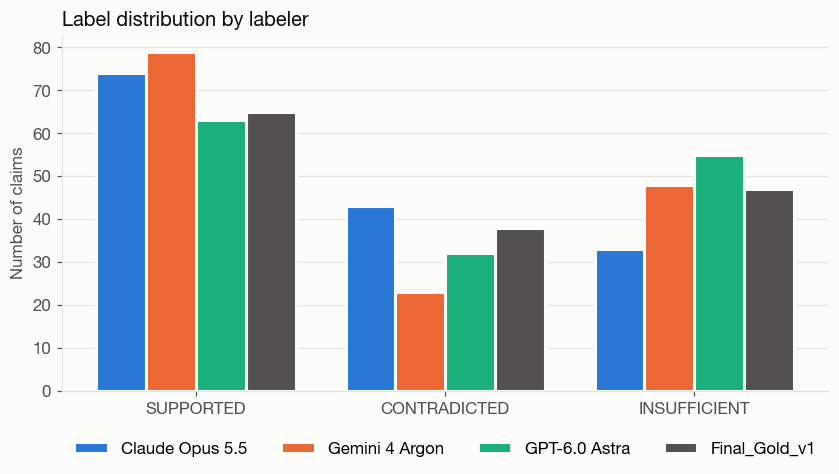

,Claude Opus 5.5,Gemini 4 Argon,GPT-6.0 Astra,Final_Gold_v1
SUPPORTED,74,79,63,65
CONTRADICTED,43,23,32,38
INSUFFICIENT,33,48,55,47


In [9]:
series = MODELS + ["Final_Gold_v1"]
dist = pd.DataFrame({s: df[s].value_counts().reindex(LABELS, fill_value=0) for s in series})
x = np.arange(len(LABELS)); w = 0.2
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, s in enumerate(series):
    ax.bar(x + (i - 1.5) * w, dist[s], w, color=COLOR[s], label=s, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(x, [SHORT[l] for l in LABELS]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Number of claims"); ax.set_title("Label distribution by labeler")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "label_distribution"); plt.show()
dist.rename(index=SHORT)

## 4 · ตรงกับ Final_Gold_v1 แค่ไหน
แท่งอ่อน = ทั้ง 150 ข้อ (ได้เปรียบเพราะข้อที่ตอบตรงกันนับเป็นถูกอัตโนมัติ) แท่งเข้ม = **เฉพาะข้อที่ AI เห็นไม่ตรงกัน** ซึ่งเป็นตัวเลขที่บอกความต่างจริง

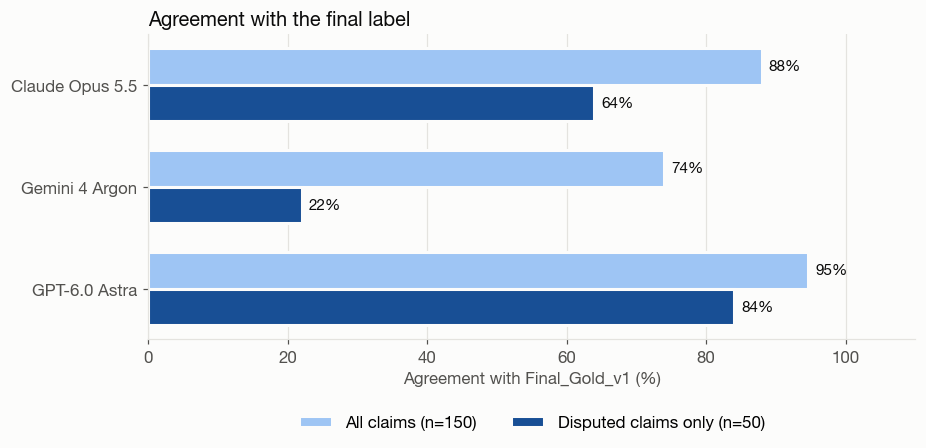

,model,subset,n,accuracy,macro_f1,cohen_kappa
0,Claude Opus 5.5,All claims,150,0.880,0.870,0.814
1,Claude Opus 5.5,Disputed claims only,50,0.640,0.591,0.460
2,Gemini 4 Argon,All claims,150,0.740,0.710,0.589
3,Gemini 4 Argon,Disputed claims only,50,0.220,0.201,-0.133
4,GPT-6.0 Astra,All claims,150,0.947,0.940,0.918
5,GPT-6.0 Astra,Disputed claims only,50,0.840,0.838,0.732


In [10]:
rows = []
for m in MODELS:
    for name, sub in (("All claims", df), ("Disputed claims only", df[df.disputed])):
        r = classification_metrics(list(sub["Final_Gold_v1"]), list(sub[m]))
        rows.append({"model": m, "subset": name, "n": r["n"], "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "cohen_kappa": cohen_kappa(list(zip(sub["Final_Gold_v1"], sub[m])))})
scores = pd.DataFrame(rows)
subsets = ["All claims", "Disputed claims only"]; shade = {subsets[0]: BLUES[1], subsets[1]: BLUES[5]}
y = np.arange(len(MODELS)); h = 0.36
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, s in enumerate(subsets):
    v = scores[scores.subset == s].set_index("model").loc[MODELS, "accuracy"]
    bars = ax.barh(y + (i - 0.5) * h, v * 100, h, color=shade[s], label=f"{s} (n={scores[scores.subset == s].n.iloc[0]})",
                   edgecolor=SURFACE, linewidth=2)
    for b, val in zip(bars, v):
        ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{val:.0%}", va="center", color=INK, fontsize=10)
ax.set_yticks(y, MODELS); ax.invert_yaxis(); ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
ax.set_xlabel("Agreement with Final_Gold_v1 (%)"); ax.set_title("Agreement with the final label")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
save(fig, "accuracy_vs_final"); plt.show()
scores.round(3)

## 5 · แยกตามหมวด claim
หมวดตัวเลขตรวจได้ตรง ๆ จึงควรสูงทุกตัว ความต่างระหว่างโมเดลจะอยู่ที่หมวดตีความและกำกวม

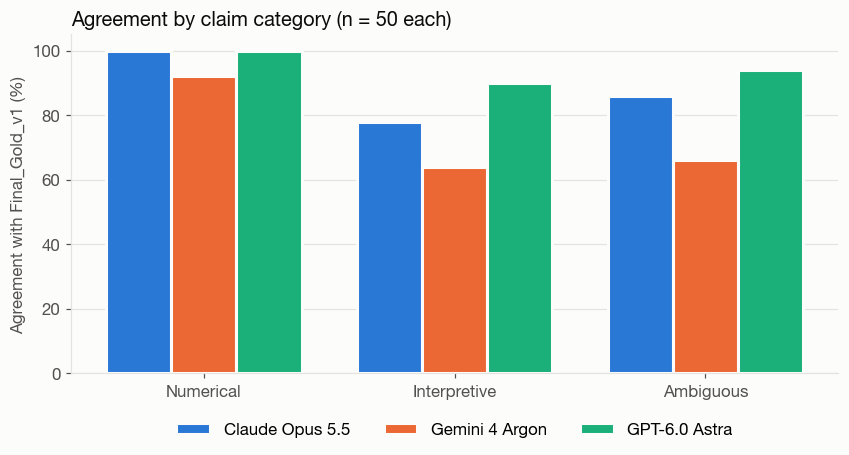

,Claude Opus 5.5,Gemini 4 Argon,GPT-6.0 Astra
numerical,100.0,92.0,100.0
interpretive,78.0,64.0,90.0
ambiguous,86.0,66.0,94.0


In [11]:
cats = ["numerical", "interpretive", "ambiguous"]
acc = pd.DataFrame({m: [(df[df.category == c][m] == df[df.category == c]["Final_Gold_v1"]).mean() for c in cats] for m in MODELS},
                   index=cats)
x = np.arange(len(cats)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 4))
for i, m in enumerate(MODELS):
    ax.bar(x + (i - 1) * w, acc[m] * 100, w, color=COLOR[m], label=m, edgecolor=SURFACE, linewidth=2)
ax.set_xticks(x, [c.capitalize() for c in cats]); ax.set_ylim(0, 105); ax.grid(axis="x", visible=False)
ax.set_ylabel("Agreement with Final_Gold_v1 (%)"); ax.set_title("Agreement by claim category (n = 50 each)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
save(fig, "accuracy_by_category"); plt.show()
(acc * 100).round(1)

## 6 · ตอบผิดเป็นอะไร (confusion matrix)
แถว = label สุดท้าย, คอลัมน์ = สิ่งที่โมเดลตอบ ตัวเลขบนเส้นทแยงคือข้อที่ตรงกัน ช่องนอกเส้นทแยงบอกว่าโมเดลมักพลาดไปทางไหน

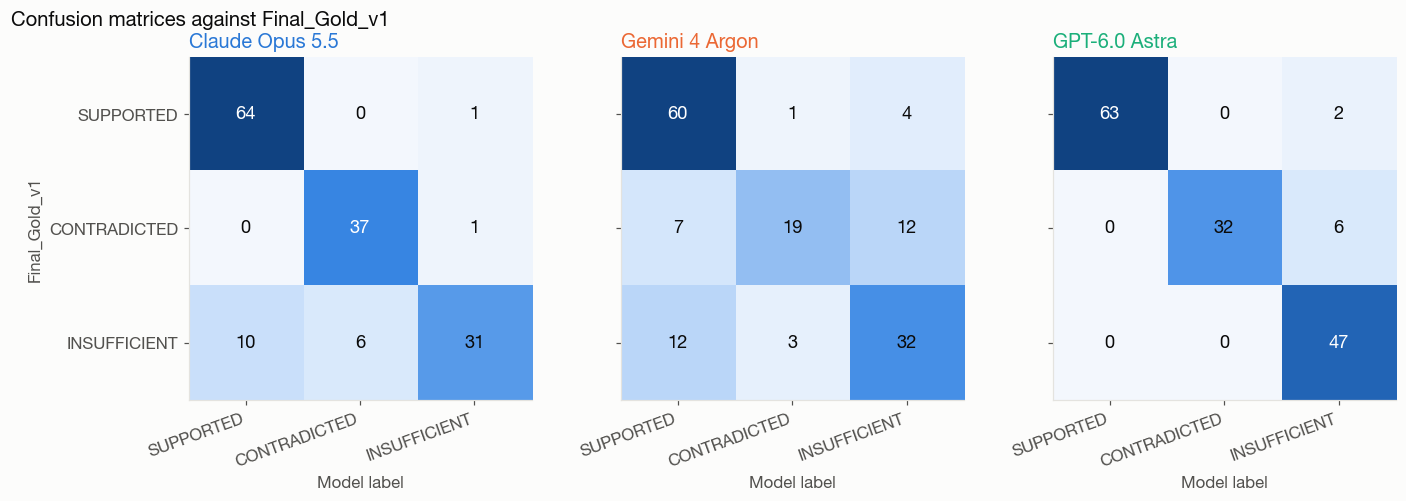

In [12]:
cmap = LinearSegmentedColormap.from_list("blue", ["#f3f7fd"] + BLUES)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, m in zip(axes, MODELS):
    cm = pd.crosstab(df["Final_Gold_v1"], df[m]).reindex(index=LABELS, columns=LABELS, fill_value=0)
    ax.imshow(cm.values, cmap=cmap, vmin=0, vmax=cm.values.max())
    for i in range(3):
        for j in range(3):
            v = cm.values[i, j]
            ax.text(j, i, v, ha="center", va="center", fontsize=12,
                    color="white" if v > cm.values.max() * 0.55 else INK, fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(3), [SHORT[l] for l in LABELS], rotation=20, ha="right")
    ax.set_yticks(range(3), [SHORT[l] for l in LABELS]); ax.grid(False)
    ax.set_title(m, color=COLOR[m]); ax.set_xlabel("Model label")
axes[0].set_ylabel("Final_Gold_v1")
fig.suptitle("Confusion matrices against Final_Gold_v1", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "confusion"); plt.show()

## 7 · หลักฐานมีอยู่ในรายงานจริงไหม
ตรวจข้อความในช่อง “ข้อความคัดลอก” ของทุกแถวกับไฟล์รายงาน SEC ในคลัง (แถวแบบ xbrl_fact ไม่มีข้อความ จึงไม่นับ)

- **Verbatim** = พบข้อความในรายงาน (รวมที่ต่างแค่ช่องว่าง/เครื่องหมาย ≥ 80%)
- **Reformatted, numbers match** = เช่น พิมพ์แถวตารางใหม่ ตัวเลขทุกตัวพบในรายงาน
- **Not found** = ทั้งถ้อยคำและตัวเลขไม่พบในรายงาน

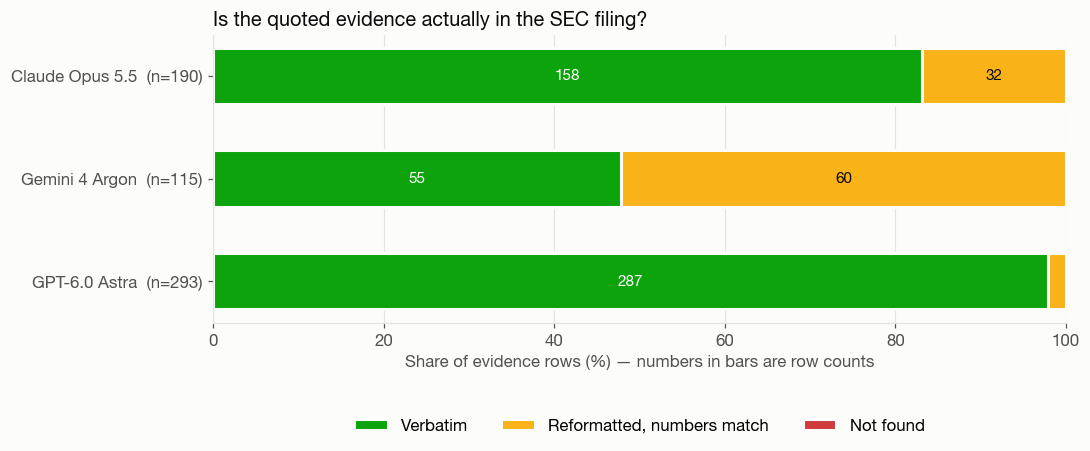

verdict,Verbatim,"Reformatted, numbers match",Not found,Total
model,,,,
Claude Opus 5.5,158,32,0,190
Gemini 4 Argon,55,60,0,115
GPT-6.0 Astra,287,6,0,293


In [13]:
man = {f["accession_number"]: f for f in aw.load_manifest()}
def norm(s):
    s = str(s).translate(str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"', "—": "-", "–": "-"}))
    return re.sub(r"[^a-z0-9%$.]+", " ", s.lower()).strip()
_docs = {}
def doc(acc):
    if acc not in _docs:
        f = man.get(acc)
        _docs[acc] = norm(document_text(acc, f["primary_document"])) if f else None
    return _docs[acc]
def verdict(acc, quote):
    t = doc(acc)
    if t is None:
        return "Not found"
    q = norm(quote); w = q.split()
    if q in t:
        return "Verbatim"
    shingles = [" ".join(w[j:j + 6]) for j in range(max(1, len(w) - 5))]
    if sum(s in t for s in shingles) / len(shingles) >= 0.8:
        return "Verbatim"
    nums = re.findall(r"\d[\d,]*\.?\d*", str(quote))
    return "Reformatted, numbers match" if nums and all(norm(n).rstrip(".") in t for n in nums) else "Not found"

ev_rows = []
for m in MODELS:
    for cid, side, kind, acc, loc, quote, concept, pe in evidence[m]:
        if kind == "xbrl_fact" or not quote:
            continue
        ev_rows.append({"model": m, "claim_id": cid, "accession": acc, "verdict": verdict(acc, quote), "quote": str(quote)[:160]})
ev = pd.DataFrame(ev_rows)
kinds = ["Verbatim", "Reformatted, numbers match", "Not found"]
kcolor = dict(zip(kinds, [STATUS["good"], STATUS["warning"], STATUS["critical"]]))
tab = ev.groupby(["model", "verdict"]).size().unstack(fill_value=0).reindex(index=MODELS, columns=kinds, fill_value=0)
share = tab.div(tab.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(MODELS))
for k in kinds:
    bars = ax.barh(MODELS, share[k] * 100, left=left * 100, color=kcolor[k], label=k, height=0.55, edgecolor=SURFACE, linewidth=2)
    for b, n, s in zip(bars, tab[k], share[k]):
        if s >= 0.06:
            ax.text(b.get_x() + b.get_width() / 2, b.get_y() + b.get_height() / 2, f"{n}",
                    ha="center", va="center", color="white" if k != "Reformatted, numbers match" else INK, fontsize=10)
    left += share[k].values
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_yticks(range(len(MODELS)), [f"{m}  (n={tab.loc[m].sum()})" for m in MODELS])
ax.set_xlabel("Share of evidence rows (%) — numbers in bars are row counts"); ax.set_title("Is the quoted evidence actually in the SEC filing?")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28))
save(fig, "evidence_verification"); plt.show()
tab.assign(Total=tab.sum(axis=1))

In [14]:
# rows whose quote could not be found in the filing (if any)
ev[ev.verdict == "Not found"][["model", "claim_id", "accession", "quote"]]

,model,claim_id,accession,quote
